# Huy · Loss, trainer và checkpoint

Chạy một ví dụ loss và gradient với code gốc, rồi xem đường học của A/B/C và các minh chứng về pilot, overfit và resume. Các biểu đồ đọc log đã lưu.

Notebook đã lưu sẵn bảng và hình. Để chạy lại, chọn kernel Python của đồ án trong VS Code hoặc Jupyter rồi bấm **Run All**. Môi trường dùng các gói trong [requirements.txt](../../../requirements.txt) và [requirements-notebook.txt](../../../requirements-notebook.txt).

In [1]:
from pathlib import Path
import json
import sys

cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "unet-vs-unetplusplus-polyp")
root = next(
    (folder for folder in candidates if (folder / "project.py").is_file()
     and (folder / "configs" / "protocol_lock.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục đồ án hoặc thư mục members/<tên>/works_done.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
colors = {"A": "#345e86", "B": "#b76b21", "C": "#187c70"}

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

## BCEWithLogits và soft Dice

[losses.py](losses.py) tính trung bình theo từng ảnh. Với cấu hình nhóm, loss bằng 0,5 × BCEWithLogits + 0,5 × (1 − soft Dice). A/B trả một tensor logits. Khi train C, loss là trung bình đều của cả bốn head. Ví dụ 2×2 dưới đây dùng dữ liệu giả lập để thấy gradient của từng head.

In [2]:
import torch

from members.huy.works_done.losses import BCESoftDiceLoss, deep_supervision_loss
from members.tri.works_done.metrics import last_logits

cfg = read_json(root / "configs/unetplusplus_ds.json")
criterion = BCESoftDiceLoss(**cfg["loss"])
target = torch.tensor([[[[1.0, 0.0], [0.0, 1.0]]]])
base = torch.tensor([[[[0.8, 0.3], [-0.3, -0.8]]]])
heads = [(scale * base).requires_grad_() for scale in (0.25, 0.5, 0.75, 1.0)]
training_loss = deep_supervision_loss(heads, target, criterion)
head_losses = [criterion(head, target).item() for head in heads]
training_loss.backward()
display(pd.DataFrame({
    "Head": [1, 2, 3, 4],
    "Loss": head_losses,
    "Chuẩn L2 của gradient logits": [head.grad.norm().item() for head in heads],
}).set_index("Head").round(6))
print(f"Train C (trung bình bốn head): {training_loss.item():.6f}")
print(f"Cùng ví dụ với quy tắc validation (head cuối): {criterion(last_logits(heads), target).item():.6f}")

,Loss,Chuẩn L2 của gradient logits
Head,,
1,0.597997,0.047442
2,0.602243,0.047211
3,0.609237,0.046853
4,0.618864,0.046406


Train C (trung bình bốn head): 0.607085
Cùng ví dụ với quy tắc validation (head cuối): 0.618864


## Lịch sử huấn luyện A/B/C đã lưu

[training.py](training.py) dùng chung epoch loop cho ba cấu hình. Train áp dụng augmentation và cập nhật Adam, validation chạy FP32 với head cuối. Best được chọn theo Dice trên validation, ưu tiên loss thấp hơn khi Dice bằng nhau. [run_utils.py](run_utils.py) quản lý seed, cấu hình và trạng thái lưu/nạp. [extended_training.py](extended_training.py) bổ sung cosine/warmup và tùy chọn khởi tạo cho các run riêng.

In [3]:
lock = read_json(root / "configs/protocol_lock.json")
runs = {
    entry["label"]: (root / entry["checkpoint_path"]).parent
    for entry in lock["experiments"]
}
histories = {label: pd.read_csv(folder / "history.csv") for label, folder in runs.items()}
summaries = {label: read_json(folder / "summary.json") for label, folder in runs.items()}
display(pd.DataFrame([
    {
        "Run": label,
        "Epoch đã chạy": summary["epochs_completed"],
        "Best epoch": summary["best"]["epoch"],
        "Best val Dice": summary["best"]["val_dice"],
        "Best val IoU": summary["best"]["val_iou"],
        "Precision train": summary["training_precision"],
        "Ảnh test đã đọc trong train": summary["test_images_read"],
    }
    for label, summary in summaries.items()
]).set_index("Run").round(4))

,Epoch đã chạy,Best epoch,Best val Dice,Best val IoU,Precision train,Ảnh test đã đọc trong train
Run,,,,,,
A,50,50,0.6337,0.5203,amp_bfloat16,0
B,50,49,0.7116,0.5859,amp_bfloat16,0
C,50,48,0.7888,0.6845,amp_bfloat16,0


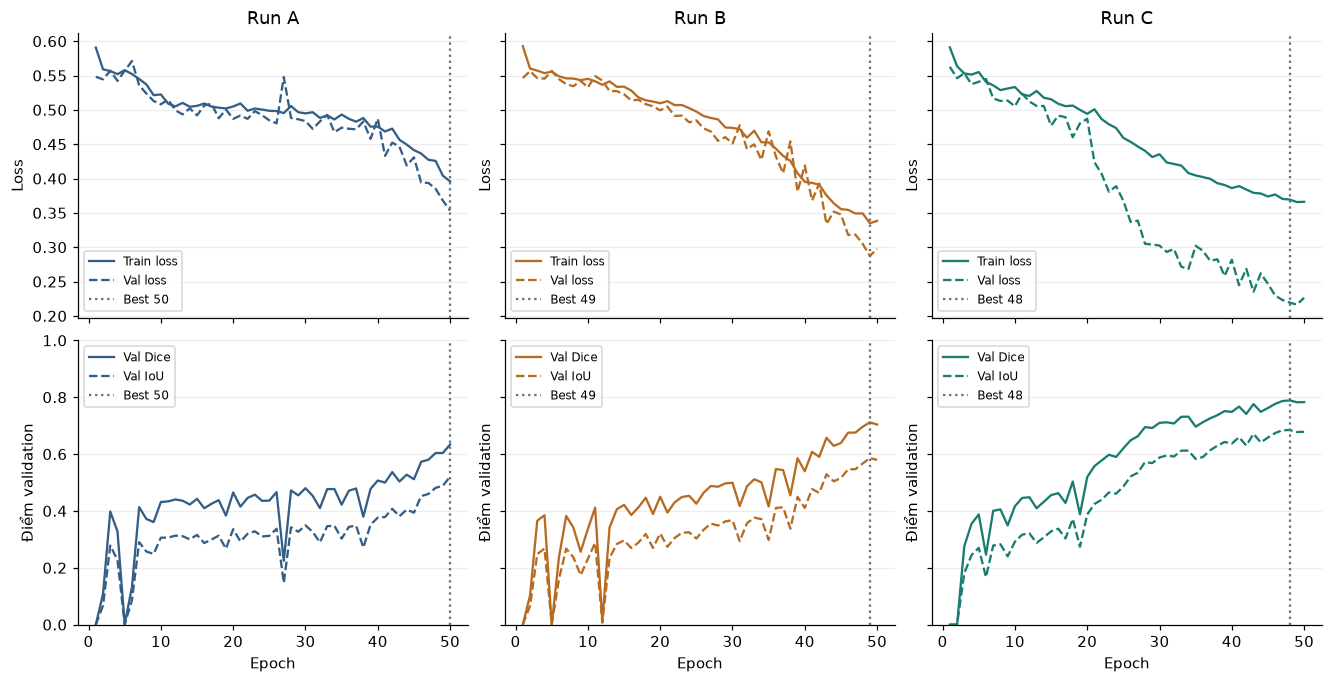

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.1), sharex="col", sharey="row", layout="constrained")
for (label, history), (loss_ax, score_ax) in zip(histories.items(), axes.T):
    best_epoch = summaries[label]["best"]["epoch"]
    loss_ax.plot(history["epoch"], history["train_loss"], color=colors[label], label="Train loss")
    loss_ax.plot(history["epoch"], history["val_loss"], color=colors[label], ls="--", label="Val loss")
    loss_ax.set(title=f"Run {label}", ylabel="Loss")
    score_ax.plot(history["epoch"], history["val_dice"], color=colors[label], label="Val Dice")
    score_ax.plot(history["epoch"], history["val_iou"], color=colors[label], ls="--", label="Val IoU")
    score_ax.set(xlabel="Epoch", ylabel="Điểm validation", ylim=(0, 1))
    for ax in (loss_ax, score_ax):
        ax.axvline(best_epoch, color="#65717c", ls=":", label=f"Best {best_epoch}")
        ax.grid(axis="y", alpha=0.22)
        ax.legend(fontsize=8)
plt.show()

Với C, train loss lấy trung bình bốn head còn val loss dùng head cuối. Augmentation cũng chỉ áp dụng ở train, nên khi so hai đường loss cần xét cả cách tính và đầu vào.

## Pilot, học thuộc mẫu nhỏ và resume

[verify_training_real.py](verify_training_real.py) xuất minh chứng pilot, overfit và checkpoint. Pilot chỉ chạy một vài epoch. Bài overfit theo dõi hai ảnh train của bài chẩn đoán. Phép thử resume so khớp run A hai epoch trên cùng môi trường.

,run_id,epoch,train_loss,val_loss,val_dice
0,pilot_A,1,0.5902,0.5556,0.0000
1,pilot_A,2,0.5598,0.5446,0.2156
2,pilot_B,1,0.5930,0.5484,0.0000
3,pilot_C,1,0.5911,0.5492,0.0000


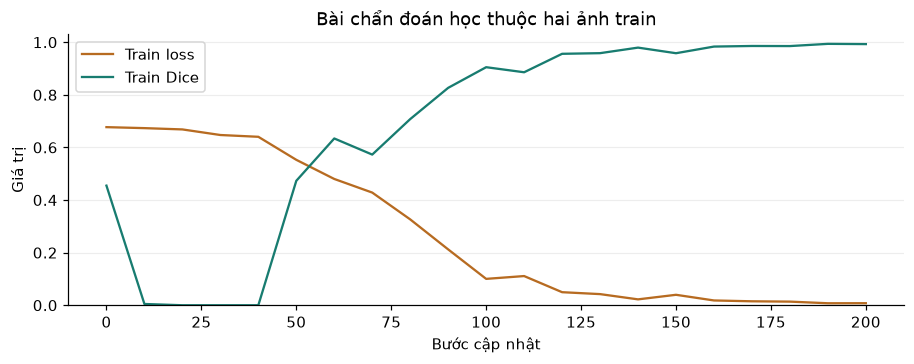

Resume A / U-Net sau 2 epoch: khớp run liên tục = True


In [5]:
evidence = root / "members/huy/works_done/evidence_training_20261014"
pilot = pd.read_csv(evidence / "pilot_history.csv")
display(pilot.loc[pilot["run_id"].str.startswith("pilot_"),
                  ["run_id", "epoch", "train_loss", "val_loss", "val_dice"]].round(4))

overfit = pd.read_csv(evidence / "overfit_history.csv")
fig, ax = plt.subplots(figsize=(8.2, 3.2), layout="constrained")
ax.plot(overfit["step"], overfit["loss"], color=colors["B"], label="Train loss")
ax.plot(overfit["step"], overfit["mean_dice"], color=colors["C"], label="Train Dice")
ax.set(title="Bài chẩn đoán học thuộc hai ảnh train", xlabel="Bước cập nhật", ylabel="Giá trị", ylim=(0, 1.03))
ax.legend()
ax.grid(axis="y", alpha=0.22)
plt.show()

resume = read_json(evidence / "verification_summary.json")["resume"]
print(f"Resume {resume['model']} sau {resume['epochs']} epoch: "
      f"khớp run liên tục = {resume['continuous_vs_resumed_exact']}")

`best.pt` lưu checkpoint dùng để đánh giá theo validation. `last.pt` giữ trạng thái epoch gần nhất để tiếp tục huấn luyện, gồm optimizer, RNG, lịch sử và patience. [train.py](train.py) là điểm vào trainer từ CLI. Các lệnh train và resume nằm trong [README của đồ án](../../../README.md).